# Phase 6 — Cluster-Consistency Layer (second-stage stacking)

**Question.** Phase 5's pairwise model scores each candidate alone. But the true matches of one S1 entity are records of the *same business*
(one or more from S2, one or more from S3), so they resemble **each other**, whereas a look-alike decoy does not. Does using the *other candidates of
the same query* improve precision — which is what F0.5 rewards?

**Method (leak-safe stacking).**
1. First stage = the Phase 5 model (69 features). For the training queries its probabilities are **out-of-fold** (5-fold, grouped by query), so the second stage never sees
   probabilities produced by a model that trained on the same query.
2. Cluster features: candidate-to-candidate affinity (name + address similarity) combined with the first-stage probabilities — support from similar candidates,
   cross-source (S2↔S3) support, strongest *dissimilar* competitor, and list-wise statistics.
3. Second stage = same classifier on [69 features + cluster features].

**Discipline.**
- Same 80/20 **train-query** split as Phase 5 (identical hold-out); the val set is **not touched**.
- The hold-out first-stage probabilities come from a model trained only on the 80 % fit queries.
- **Adopt rule (printed):** ΔPR-AUC ≥ 0.002 **and** Δ best-threshold macro F0.5 ≥ 0.003 **and** the paired-bootstrap 95 % interval of ΔF0.5 is entirely above 0.
  (Both models use their own best hold-out threshold, so the comparison is equally optimistic for each.)

**Sections:** 1 Load → 2 Is there cluster signal? → 3 First stage (out-of-fold) → 4 Cluster features + second stage → 5 Significance + where it helps → 6 Decision + save

In [1]:
import os, sys, json, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import cluster_features as CF
import eval_utils as EU

ROOT = "../../../"; INTERIM = ROOT + "dataset/interim"
CFG = json.load(open("retrieval_config.json"))
FL = json.load(open("feature_list.json"))
FEATS = FL["final_features"]
SEED = 42
pd.set_option("display.width", 170)
print(f"first-stage features: {len(FEATS)} (groups {FL['final_groups']})")

first-stage features: 69 (groups ['name_basic', 'name_structural', 'addr_basic', 'addr_numbers', 'relative'])


## 1. Load (train candidates + features + truth counts) and rebuild the Phase 5 hold-out

In [2]:
ctr = pd.read_pickle(INTERIM + "/candidates_train.pkl")
Ftr = pd.read_pickle(INTERIM + "/features_train.pkl")
P4 = pickle.load(open(INTERIM + "/phase4_truth_and_queries.pkl", "rb"))
ntrue = P4["truth"]["train"].groupby("s1_id").size()
ents = P4["queries"][P4["queries"]["split"] == "train"]["s1_id"].tolist()
assert len(ctr) == len(Ftr)
y = ctr["label"].values; qid = ctr["s1_id"].values

rng = np.random.default_rng(SEED)
tr_ent = np.array(ents); hold = set(rng.choice(tr_ent, int(0.2 * len(tr_ent)), replace=False))   # identical to Phase 5
is_hold = ctr["s1_id"].isin(hold).values
ent_hold = [e for e in ents if e in hold]
print(f"fit pairs {(~is_hold).sum():,} ({len(ents)-len(ent_hold):,} queries) | hold-out pairs {is_hold.sum():,} ({len(ent_hold):,} queries)")

STR_P = INTERIM + "/phase6_strings.pkl"
if os.path.exists(STR_P):
    name_n, addr_n = pickle.load(open(STR_P, "rb"))
else:
    t0 = time.time(); name_n, addr_n = CF.prep_strings(ctr, CFG); pickle.dump((name_n, addr_n), open(STR_P, "wb"))
    print(f"normalized candidate strings in {time.time()-t0:.0f}s")
src_is_s2 = ctr["cand_id"].str.startswith("S2").values

fit pairs 728,784 (19,200 queries) | hold-out pairs 181,999 (4,800 queries)


normalized candidate strings in 35s


## 2. Is there cluster signal at all? (train, 3,000-query sample)
Mean candidate-to-candidate affinity for three kinds of pairs inside one query's list: **true–true** (two records of the same business),
**true–false**, **false–false**. If true–true is clearly higher than the others, cluster features have something to use.

,n,mean affinity,median,share >= 0.8
pair type,,,,
true–true,15117,0.797,0.815,0.559
true–false,325291,0.486,0.475,0.011
false–false,1772949,0.434,0.400,0.024


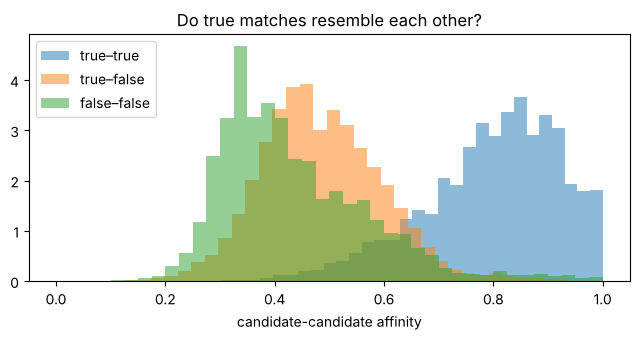

In [3]:
smp = np.random.default_rng(1).choice(ents, 3000, replace=False)
grp = pd.Series(np.arange(len(ctr))).groupby(qid).indices
tt, tf, ff = [], [], []
for q in smp:
    ix = grp[q]
    if len(ix) < 2: continue
    A = CF.affinity(list(name_n[ix]), list(addr_n[ix])); l = y[ix].astype(bool)
    iu = np.triu_indices(len(ix), 1); a = A[iu]; li, lj = l[iu[0]], l[iu[1]]
    tt += a[li & lj].tolist(); tf += a[li ^ lj].tolist(); ff += a[~li & ~lj].tolist()
sig = pd.DataFrame({"pair type": ["true–true", "true–false", "false–false"], "n": [len(tt), len(tf), len(ff)],
                    "mean affinity": [np.mean(tt), np.mean(tf), np.mean(ff)], "median": [np.median(tt), np.median(tf), np.median(ff)],
                    "share >= 0.8": [np.mean(np.array(tt) >= .8), np.mean(np.array(tf) >= .8), np.mean(np.array(ff) >= .8)]}).set_index("pair type")
display(sig.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for v, lab in [(tt, "true–true"), (tf, "true–false"), (ff, "false–false")]: ax.hist(v, bins=40, alpha=.5, density=True, label=lab)
ax.set_xlabel("candidate-candidate affinity"); ax.legend(); ax.set_title("Do true matches resemble each other?"); plt.tight_layout(); plt.show()

## 3. First stage: out-of-fold probabilities
5-fold, grouped by query, on the 80 % fit queries → leak-free probabilities for fit rows. One model on all fit queries → probabilities for the hold-out.

In [4]:
def hgb(): return HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, max_leaf_nodes=31, random_state=SEED)
CACHE = INTERIM + "/phase6_stage1.pkl"
if os.path.exists(CACHE):
    p_all = pickle.load(open(CACHE, "rb"))
else:
    t0 = time.time(); X = Ftr[FEATS].values
    fit_idx = np.flatnonzero(~is_hold); p_all = np.zeros(len(ctr))
    for k, (a, b) in enumerate(GroupKFold(5).split(fit_idx, y[fit_idx], groups=qid[fit_idx])):
        m = hgb().fit(X[fit_idx[a]], y[fit_idx[a]]); p_all[fit_idx[b]] = m.predict_proba(X[fit_idx[b]])[:, 1]
        print(f"  fold {k+1}/5 done ({time.time()-t0:.0f}s)")
    m = hgb().fit(X[fit_idx], y[fit_idx]); p_all[is_hold] = m.predict_proba(X[is_hold])[:, 1]
    pickle.dump(p_all, open(CACHE, "wb")); print(f"first stage done in {time.time()-t0:.0f}s")
yH, qH, pH = y[is_hold], qid[is_hold], p_all[is_hold]
t1, f1, _ = EU.best_threshold(ent_hold, ntrue, qH, yH, pH)
base = dict(pr_auc=float(average_precision_score(yH, pH)), macro_f05=float(f1), thr=float(t1))
print(f"FIRST STAGE on hold-out: PR-AUC {base['pr_auc']:.4f} | best-threshold macro F0.5 {base['macro_f05']:.4f} @ {base['thr']:.2f}")
print(f"OOF sanity (fit rows): PR-AUC {average_precision_score(y[~is_hold], p_all[~is_hold]):.4f} (should be close to hold-out)")

  fold 1/5 done (19s)


  fold 2/5 done (43s)


  fold 3/5 done (64s)


  fold 4/5 done (87s)


  fold 5/5 done (105s)


first stage done in 132s


FIRST STAGE on hold-out: PR-AUC 0.9936 | best-threshold macro F0.5 0.9465 @ 0.70


OOF sanity (fit rows): PR-AUC 0.9909 (should be close to hold-out)


## 4. Cluster features and the second stage
Cluster feature groups are added cumulatively: **listwise** (the first-stage probability, its rank/margin within the query, expected number of matches) →
**support** (similar candidates that the first stage believes in, cross-source S2↔S3 support) → **competitor** (a strong candidate that is *unlike* this one).

In [5]:
t0 = time.time()
CL = CF.cluster_features(qid, name_n, addr_n, src_is_s2, p_all)
print(f"cluster features {CL.shape} in {time.time()-t0:.0f}s")
X1 = Ftr[FEATS]
RUNS = INTERIM + "/phase6_stage2.json"
cache = json.load(open(RUNS)) if os.path.exists(RUNS) else {}
scores = {}
def stage2(groups, key):
    cols = [c for g in groups for c in CF.GROUPS[g]]
    X = pd.concat([X1, CL[cols]], axis=1).values
    m = hgb().fit(X[~is_hold], y[~is_hold]); s = m.predict_proba(X[is_hold])[:, 1]
    scores[key] = s
    t, f, _ = EU.best_threshold(ent_hold, ntrue, qH, yH, s)
    out = dict(n_features=X.shape[1], pr_auc=float(average_precision_score(yH, s)), macro_f05=float(f), thr=float(t))
    cache[key] = out; json.dump(cache, open(RUNS, "w")); return out
rows = [dict(model="first stage only (Phase 5)", n_features=len(FEATS), **{k: base[k] for k in ["pr_auc", "macro_f05", "thr"]})]
steps = [["listwise"], ["listwise", "support"], ["listwise", "support", "competitor"]]
for g in steps:
    key = "+".join(g); r = stage2(g, key); rows.append(dict(model="+ " + key, **r)); print(f"{key:32s} PR-AUC {r['pr_auc']:.4f}  F0.5 {r['macro_f05']:.4f}")
res = pd.DataFrame(rows).set_index("model")
res["d_pr_auc"] = res["pr_auc"] - base["pr_auc"]; res["d_f05"] = res["macro_f05"] - base["macro_f05"]
display(res.round(4))

cluster features (910783, 13) in 36s


listwise                         PR-AUC 0.9933  F0.5 0.9446


listwise+support                 PR-AUC 0.9907  F0.5 0.9451


listwise+support+competitor      PR-AUC 0.9917  F0.5 0.9463


,n_features,pr_auc,macro_f05,thr,d_pr_auc,d_f05
model,,,,,,
first stage only (Phase 5),69,0.9936,0.9465,0.70,0.0000,0.0000
+ listwise,74,0.9933,0.9446,0.70,-0.0003,-0.0018
+ listwise+support,80,0.9907,0.9451,0.75,-0.0029,-0.0014
+ listwise+support+competitor,82,0.9917,0.9463,0.65,-0.0019,-0.0002


## 5. Is the gain real, and where does it come from?
Paired bootstrap over hold-out **entities** (1,000 resamples) of the F0.5 difference between the best second-stage set and the first stage,
each at its own best threshold. Then the difference split by country.

In [6]:
best_key = res.iloc[1:]["macro_f05"].idxmax().replace("+ ", "")
bst = cache[best_key]
_, f_base = EU.macro_f05(ent_hold, ntrue, qH, yH, (pH >= base["thr"]).astype(int))
_, f_new = EU.macro_f05(ent_hold, ntrue, qH, yH, (scores[best_key] >= bst["thr"]).astype(int))
d = (f_new - f_base).values
bs = np.random.default_rng(SEED).choice(d, (1000, len(d)), replace=True).mean(1)
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"best second-stage set: {best_key}")
print(f"ΔF0.5 = {d.mean():+.4f}  (95% bootstrap interval [{lo:+.4f}, {hi:+.4f}]) | entities improved {np.mean(d > 1e-9):.1%}, worsened {np.mean(d < -1e-9):.1%}")
cty = ctr.loc[is_hold].groupby("s1_id")["country"].first().reindex(ent_hold)
print("ΔF0.5 by country:", pd.Series(d, index=ent_hold).groupby(cty.values).mean().round(4).to_dict())
tp_ent = pd.Series(ntrue.reindex(ent_hold).fillna(0).values, index=ent_hold)
for name, m_ in [("singletons (0 matches)", tp_ent == 0), ("1 match", tp_ent == 1), ("2+ matches", tp_ent >= 2)]:
    print(f"  {name:24s} n={int(m_.sum()):5d}  base {f_base[m_.values].mean():.4f} -> new {f_new[m_.values].mean():.4f}")

best second-stage set: listwise+support+competitor
ΔF0.5 = -0.0002  (95% bootstrap interval [-0.0021, +0.0015]) | entities improved 7.5%, worsened 3.2%


ΔF0.5 by country: {'India': 0.001, 'US': -0.001}
  singletons (0 matches)   n=  272  base 0.9559 -> new 0.9632
  1 match                  n=  250  base 0.8653 -> new 0.8365
  2+ matches               n= 4278  base 0.9506 -> new 0.9516


## 6. Decision and save

In [7]:
ADOPT = bool((bst["pr_auc"] - base["pr_auc"] >= 0.002) and (bst["macro_f05"] - base["macro_f05"] >= 0.003) and lo > 0)
groups_used = best_key.split("+") if ADOPT else []
print(f"ΔPR-AUC {bst['pr_auc']-base['pr_auc']:+.4f} (need >= +0.002) | ΔF0.5 {bst['macro_f05']-base['macro_f05']:+.4f} (need >= +0.003) | bootstrap lower bound {lo:+.4f} (need > 0)")
print("DECISION: cluster layer", "ADOPTED" if ADOPT else "NOT adopted", "->", groups_used or "pairwise model only")
json.dump(dict(adopt=ADOPT, groups=groups_used, cluster_columns=[c for g in groups_used for c in CF.GROUPS[g]],
               first_stage=base, second_stage=bst, delta_f05=float(d.mean()), bootstrap_95=[float(lo), float(hi)],
               rule="dPR>=0.002 and dF05>=0.003 and bootstrap lower>0"), open("cluster_config.json", "w"), indent=2)
print("\n=== PHASE 6 SUMMARY ===")
print(f"Cluster signal: mean affinity true–true {np.mean(tt):.3f} vs true–false {np.mean(tf):.3f} vs false–false {np.mean(ff):.3f}")
print(f"First stage hold-out: PR-AUC {base['pr_auc']:.4f}, macro F0.5 {base['macro_f05']:.4f}")
print(f"Best second stage ({best_key}): PR-AUC {bst['pr_auc']:.4f}, macro F0.5 {bst['macro_f05']:.4f}")
print("Decision:", "adopt the cluster layer in Phase 8" if ADOPT else "skip the cluster layer (no reliable gain)")
print("Val set untouched. Config written: cluster_config.json")

ΔPR-AUC -0.0019 (need >= +0.002) | ΔF0.5 -0.0002 (need >= +0.003) | bootstrap lower bound -0.0021 (need > 0)
DECISION: cluster layer NOT adopted -> pairwise model only

=== PHASE 6 SUMMARY ===


Cluster signal: mean affinity true–true 0.797 vs true–false 0.486 vs false–false 0.434
First stage hold-out: PR-AUC 0.9936, macro F0.5 0.9465
Best second stage (listwise+support+competitor): PR-AUC 0.9917, macro F0.5 0.9463
Decision: skip the cluster layer (no reliable gain)
Val set untouched. Config written: cluster_config.json
